In [ ]:
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split

df = pd.read_csv('/Iris.csv')

df

,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,1,5.1,3.5,1.4,0.2,Iris-setosa
1,2,4.9,3.0,1.4,0.2,Iris-setosa
2,3,4.7,3.2,1.3,0.2,Iris-setosa
3,4,4.6,3.1,1.5,0.2,Iris-setosa
4,5,5.0,3.6,1.4,0.2,Iris-setosa
...,...,...,...,...,...,...
145,146,6.7,3.0,5.2,2.3,Iris-virginica
146,147,6.3,2.5,5.0,1.9,Iris-virginica
147,148,6.5,3.0,5.2,2.0,Iris-virginica
148,149,6.2,3.4,5.4,2.3,Iris-virginica


In [ ]:
df.head()

,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,1,5.1,3.5,1.4,0.2,Iris-setosa
1,2,4.9,3.0,1.4,0.2,Iris-setosa
2,3,4.7,3.2,1.3,0.2,Iris-setosa
3,4,4.6,3.1,1.5,0.2,Iris-setosa
4,5,5.0,3.6,1.4,0.2,Iris-setosa


In [ ]:
df.shape

(150, 6)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             150 non-null    int64  
 1   SepalLengthCm  150 non-null    float64
 2   SepalWidthCm   150 non-null    float64
 3   PetalLengthCm  150 non-null    float64
 4   PetalWidthCm   150 non-null    float64
 5   Species        150 non-null    object 
dtypes: float64(4), int64(1), object(1)
memory usage: 7.2+ KB


In [ ]:
df.isnull().sum()

,0
Id,0
SepalLengthCm,0
SepalWidthCm,0
PetalLengthCm,0
PetalWidthCm,0
Species,0


no null values are found

In [ ]:
duplicates = df[df.duplicated()]
print("Number of duplicates:", len(duplicates))

Number of duplicates: 0


In [ ]:
# Drop duplicates
df = df.drop_duplicates()

In [ ]:
df.describe()

,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm
count,150.000000,150.000000,150.000000,150.000000,150.000000
mean,75.500000,5.843333,3.054000,3.758667,1.198667
std,43.445368,0.828066,0.433594,1.764420,0.763161
min,1.000000,4.300000,2.000000,1.000000,0.100000
25%,38.250000,5.100000,2.800000,1.600000,0.300000
50%,75.500000,5.800000,3.000000,4.350000,1.300000
75%,112.750000,6.400000,3.300000,5.100000,1.800000
max,150.000000,7.900000,4.400000,6.900000,2.500000


In [ ]:
df.shape

(150, 6)

In [ ]:
count_species = df.value_counts("Species")

In [ ]:
# Checking for the correlation
df.dtypes

,0
Id,int64
SepalLengthCm,float64
SepalWidthCm,float64
PetalLengthCm,float64
PetalWidthCm,float64
Species,object


In [ ]:
print(df.columns.tolist())

['Id', 'SepalLengthCm', 'SepalWidthCm', 'PetalLengthCm', 'PetalWidthCm', 'Species']


In [ ]:
df.drop('Id',axis=1,inplace=True) #dropping the Id column

Accuracy with Logistic Regression is 93.33


In [ ]:
# Calculate the skewness for all columns
df.skew(numeric_only=True)

,0
SepalLengthCm,0.314911
SepalWidthCm,0.334053
PetalLengthCm,-0.274464
PetalWidthCm,-0.104997


In [ ]:
# Checking for the unique values
df.nunique()

,0
SepalLengthCm,35
SepalWidthCm,23
PetalLengthCm,43
PetalWidthCm,22
Species,3


In [ ]:
df.columns

Index(['SepalLengthCm', 'SepalWidthCm', 'PetalLengthCm', 'PetalWidthCm',
       'Species'],
      dtype='object')

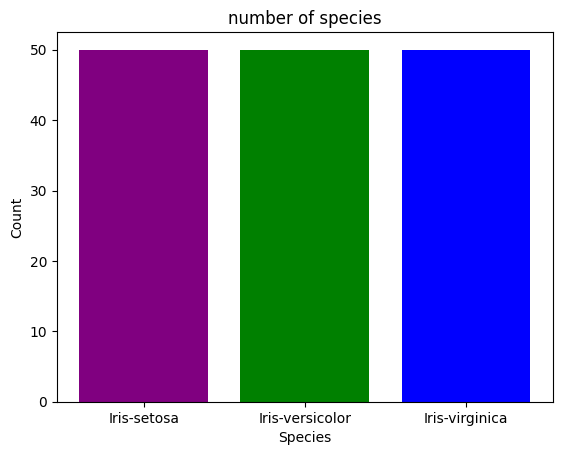

In [ ]:


import matplotlib.pyplot as plt

count_species = df.value_counts("Species")

species = count_species.index
count = count_species.values

plt.bar(species, count,color=["purple", "green", "blue"])

plt.xlabel("Species")
plt.ylabel("Count")
plt.title("number of species")
plt.show()

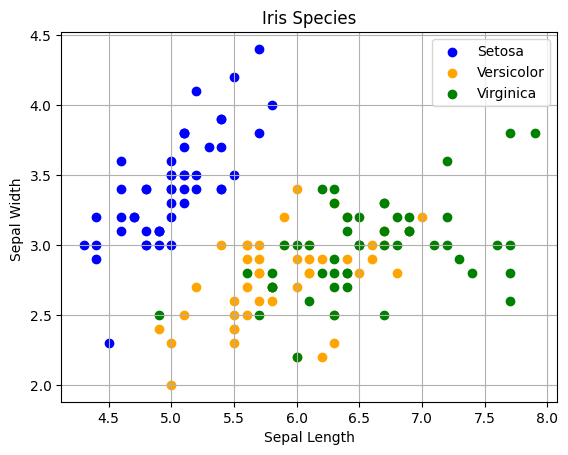

In [ ]:
import matplotlib.pyplot as plt

setosa = df[df["Species"] == "Iris-setosa"]
versicolor = df[df["Species"] == "Iris-versicolor"]
virginica = df[df["Species"] == "Iris-virginica"]

plt.scatter(
    setosa["SepalLengthCm"],
    setosa["SepalWidthCm"],
    color="blue",
    label="Setosa"
)

plt.scatter(
    versicolor["SepalLengthCm"],
    versicolor["SepalWidthCm"],
    color="orange",
    label="Versicolor"
)

plt.scatter(
    virginica["SepalLengthCm"],
    virginica["SepalWidthCm"],
    color="green",
    label="Virginica"
)

plt.xlabel("Sepal Length")
plt.ylabel("Sepal Width ")
plt.title("Iris Species")

plt.legend()
plt.grid()

plt.show()

A scatter plot shows the relationship between two numerical columns.

setosa has smaller sepal length
and higher sepal width.

versicolor  is in middle it means medium size pertals

virginicia has the largest sepal length


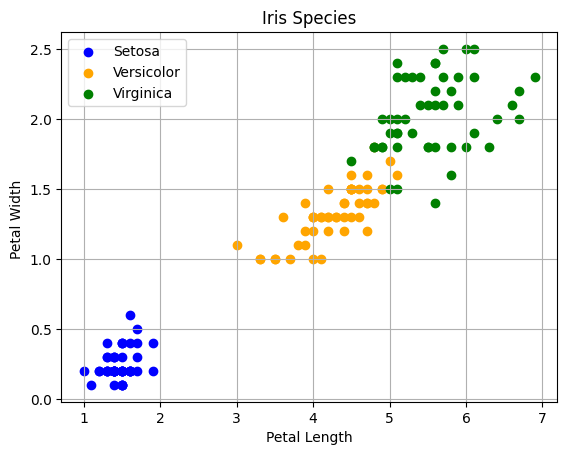

In [ ]:
import matplotlib.pyplot as plt

setosa = df[df["Species"] == "Iris-setosa"]
versicolor = df[df["Species"] == "Iris-versicolor"]
virginica = df[df["Species"] == "Iris-virginica"]

plt.scatter(
    setosa["PetalLengthCm"],
    setosa["PetalWidthCm"],
    color="blue",
    label="Setosa"
)

plt.scatter(
    versicolor["PetalLengthCm"],
    versicolor["PetalWidthCm"],
    color="orange",
    label="Versicolor"
)

plt.scatter(
    virginica["PetalLengthCm"],
    virginica["PetalWidthCm"],
    color="green",
    label="Virginica"
)

plt.xlabel("Petal Length")
plt.ylabel("Petal Width ")
plt.title("Iris Species")

plt.legend()
plt.grid()

plt.show()

Species Setosa has smaller petal lengths and widths.
Versicolor Species lies in the middle of the other two species in terms of petal length and width
Species Virginica has the largest of petal lengths and widths

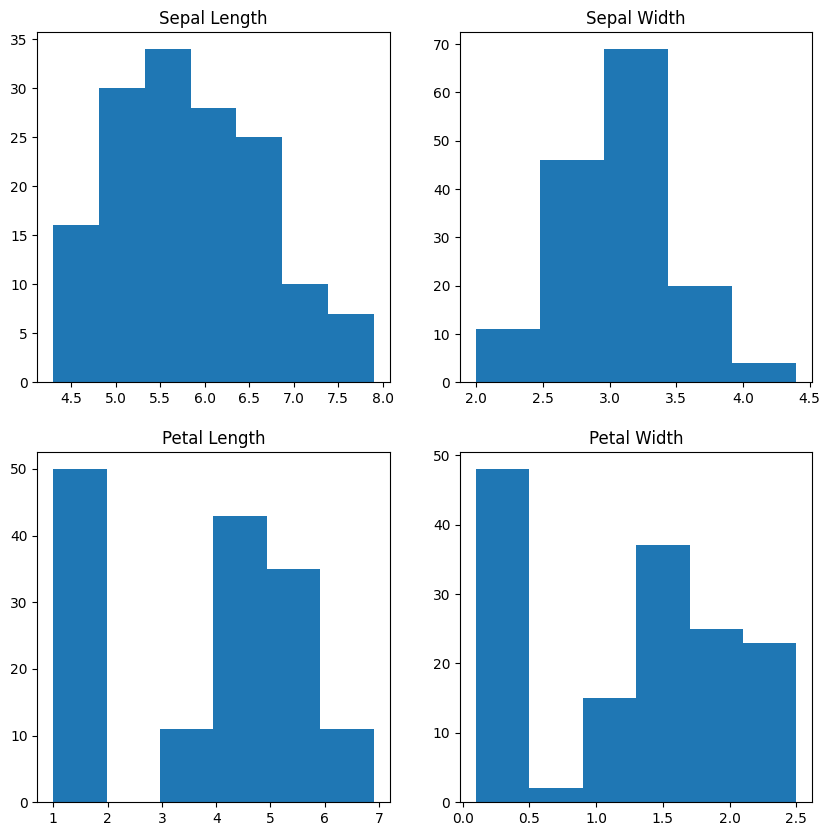

In [ ]:
import matplotlib.pyplot as plt


fig, axes = plt.subplots(2, 2, figsize=(10,10))

axes[0,0].set_title("Sepal Length")
axes[0,0].hist(df['SepalLengthCm'], bins=7)

axes[0,1].set_title("Sepal Width")
axes[0,1].hist(df['SepalWidthCm'], bins=5);

axes[1,0].set_title("Petal Length")
axes[1,0].hist(df['PetalLengthCm'], bins=6);

axes[1,1].set_title("Petal Width")
axes[1,1].hist(df['PetalWidthCm'], bins=6);

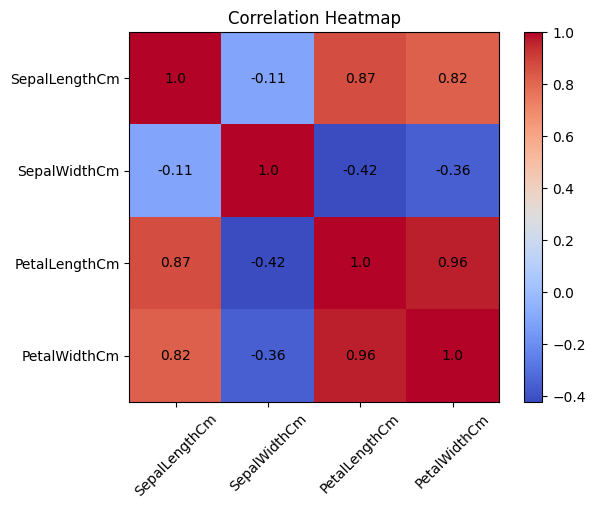

In [ ]:
import matplotlib.pyplot as plt

data = df.select_dtypes(include=["number"]) #takes only columns containgin  numbers

corr = data.corr() #calculate coorre

plt.imshow(corr, cmap="coolwarm") #display the corr matrix as image
plt.colorbar()

plt.xticks(range(len(corr.columns)), corr.columns, rotation=45)
plt.yticks(range(len(corr.columns)), corr.columns)

# Add correlation values
for i in range(len(corr.columns)):
    for j in range(len(corr.columns)):
        plt.text(
            j, i,
            round(corr.iloc[i, j], 2),
            ha="center",
            va="center"
        )

plt.title("Correlation Heatmap")
plt.show()

/tmp/ipykernel_5055/2882818376.py:7: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(numeric_df.values, labels=numeric_df.columns)


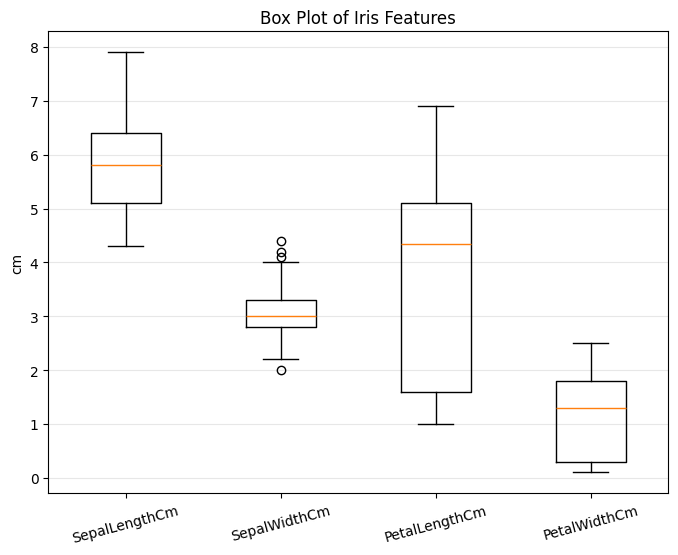

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))

numeric_df = df.select_dtypes(include='number')

plt.boxplot(numeric_df.values, labels=numeric_df.columns)
plt.title("Box Plot of Iris Features")
plt.ylabel("cm")
plt.xticks(rotation=15)
plt.grid(axis='y', alpha=0.3)
plt.show()

In [ ]:
import numpy as np
# handling outliers

# IQR
Q1 = np.percentile(df['SepalWidthCm'], 25,
				interpolation = 'midpoint')

Q3 = np.percentile(df['SepalWidthCm'], 75,
				interpolation = 'midpoint')
IQR = Q3 - Q1

print("Old Shape: ", df.shape)

# Upper
upper = np.where(df['SepalWidthCm'] >= (Q3+1.5*IQR))

# Lower
lower = np.where(df['SepalWidthCm'] <= (Q1-1.5*IQR))

# Removing the Outliers
df.drop(upper[0], inplace = True)
df.drop(lower[0], inplace = True)

print("New Shape: ", df.shape)



Old Shape:  (150, 5)
New Shape:  (146, 5)


In [ ]:
import tensorflow as tf
import sklearn.metrics as metrics

# for data splitting, transforming and model training
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import MinMaxScaler

train, test = train_test_split(data, test_size = 0.3) # the attribute test_size=0.3 splits the data into 70% and 30% ratio. train=70% and test=30%
print(train.shape)
print(test.shape)

(105, 4)
(45, 4)


In [ ]:

x = df.drop('Species', axis=1)
y = df['Species']
x_train, x_test, y_train, y_test = train_test_split(x, y, train_size=0.70)

logistic_regression = LogisticRegression()
logistic_regression.fit(x_train, y_train)
logistic_predictions = logistic_regression.predict(x_test)
print('Accuracy with Logistic Regression is %.2f' % (accuracy_score(y_test, logistic_predictions) * 100))

Accuracy with Logistic Regression is 93.18
